# Radiation and water on Pine Ridge
### Historical measurements, analytical limits, and monitoring gaps

**NIFA series Educational notebook Version 1.0 October 27, 2026**

What do documented water samples tell us about uranium and radioactivity on Pine Ridge, and what questions remain unanswered?

This notebook works with **published laboratory results** from Heakin (2000), a USGS study prepared in cooperation with the Oglala Sioux Tribe. The study spans 1992–1997.                                                                                                                      

**Run:** open in Jupyter or upload the `.ipynb` to Google Colab and run all cells. The data snapshot is embedded, so the numerical analysis runs offline once Python dependencies are installed. The companion bundle includes the CSV, source PDF, provenance, and a browser-readable copy.

**Suggested duration:** 60–90 minutes. Prerequisites: basic pandas filtering and reading a graph.

By the end, you can distinguish mass from activity concentration, retain nondetect qualifiers, interpret analytical uncertainty, identify uneven measurement coverage, and explain why a historical sample cannot establish today's conditions.

## Begin with the question

Community interest in radiation is the reason for this module.                                                                        

| Concern | Relevant medium and measurements | Included here? |
|---|---|---|
| Uranium in water | Uranium mass concentration, sample date and treatment stage | Yes |
| Radioactivity in water | Gross alpha, gross beta, radium-226 activity | Yes |
| Radon in buildings | Indoor-air radon measurements and building conditions | No |
| Soil, sediment, dust, or external exposure | Measurements specific to those media and pathways | No |
| A mining source | Site-specific transport, hydrogeological and analytical evidence | Not evaluated |

Arsenic is an important companion water-quality topic, but it is not a radionuclide and is outside this extraction. Uranium mass and activity are related through isotope composition; this notebook does not apply a universal conversion.

**Opening discussion:** Which question is most relevant locally: present water conditions, changes since historical sampling, private-well coverage, indoor radon, or another pathway? What additional evidence would that question require?

## Source and scope

**Heakin, A.J. (2000).** *Water quality of selected springs and public-supply wells, Pine Ridge Indian Reservation, South Dakota, 1992–97*. USGS Water-Resources Investigations Report 99-4063. [DOI and report](https://doi.org/10.3133/wri994063).

The extraction contains four selected analytes from Table 13 (springs, printed pp. 51–52) and Table 14 (wells, pp. 59–61). The well metadata come from Table 3 (p. 12); sampling methods are on p. 13. PDF page numbers are five higher than printed page numbers.

There are 44 public-supply well sites and 14 spring sites. The dataset includes entries marked `--` in the selected columns, so **a row is an analyte slot in a published sample record**. These are selected study sites only.

Most well samples were collected upstream of chemical treatment feeders. Sites 6, 11, and 12 were collected downstream (report p. 13). This distinction remains visible in the data.

The public report is the source for this teaching dataset. No household records from later OST/IHS collaborations are included. This draft does not claim OLC/OST endorsement or approval for public release; institutional attribution and award language can be added through the series' existing review process.

In [12]:
# Run only if your notebook environment lacks these packages:
# %pip install numpy pandas matplotlib
import base64, gzip, hashlib, io, json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display, Markdown

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titleweight': 'bold',
    'axes.labelcolor': '#263849', 'text.color': '#263849',
    'savefig.facecolor': 'white', 'figure.facecolor': 'white',
})
BLUE, TEAL, GOLD, GRAY = '#25577c', '#008577', '#bc7e17', '#dce3e8'
ANALYTES = ['uranium', 'gross_alpha', 'gross_beta', 'radium_226']
LABELS = {'uranium': 'Uranium', 'gross_alpha': 'Gross alpha (as Th-230)',
          'gross_beta': 'Gross beta (as Cs-137)', 'radium_226': 'Radium-226'}
FIGURES = []
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}')

Python 3.11.17 | NumPy 2.4.6 | pandas 3.0.6 | Matplotlib 3.11.2


### Load the auditable snapshot

The next cell is a compressed copy of the companion CSV, not generated observations. It checks the bytes against a SHA-256 digest before loading them. A copy at `data/historical_results.csv` is preferred when present and must match the same digest. The compressed fallback makes the notebook portable as a single file.

For inspection, the loaded table and every original result string remain available below. The companion `sources/` folder contains the report and extracted page text. `reextract.py` regenerates the CSV from that report with optional `pdfplumber` installed.

In [13]:
EMBEDDED_CSV_GZIP_BASE64 = 'H4sIAAAAAAACCuWdXY/juJWG7xfIfzD62vbwQxTFZG6CBAiC3audBLksuKvc3Ubcrortmtn+96sPU6Io0nRZ4pHnEEh6phs9LZ+n/b46Il8dnl7fj8/bp93L8tT82/txr//1vPm83+qfvL18eXrbfO1+ftwdztuX5tfeD8/b43lT/sqPp8Hv352bP7/65/nHW/krm+9v++3Ty6b8hdfj7uvusNkvN+UPP87b5dvmuPm+PW+PT8+vL9vlcXt635+73/Z+2J17l2On3dfvm+43fN9uTu/H8oO9Hp+2p/Pue3mVl2V9rcNr+eefj9vN+fv2cH46nauPt/nP++7L9rgsf3bevR66T1oVX3/Gy0fbPW/2Ty/b0/Nx91b9Tv3RDu/ft8fd8/I/75v97suu/KOO27fX43l3+Pr0+fX98PKH//rnL3/75elf//v3J6WeMpLz5bfz+e30x59+env/fFq/n76e1l9ff/3pt+Ou+r9S1e/p/m1dolzSbJlnS6GqH+nyt+1+vyRqxfKVypdfj6+n09Nm//ZtsyQZZfmSr8Xy7S+7n/5nydbF5fNsXxb7zefX4+b8evyxaD78cvn+dqqIfF+8flm0aJZ/Pu7+vTlut8uME8Y4JYwUmSK0u+anv+5Op9f9r+WfWl9+UV9+cdy87F43z+fdr7vzj+Vic1r849uKcfKp/kj6g7TMJkMjljmpfnSj+bw9l2S4oGLJ6AWMWCsYMNXFHVz+clpRLj+VH2hNZgBTfaD370+s/LIQJShZ/rzWZFar2GCai6+qiy/e9pvD87ftefFcauX8abncb8u/sfO3zWFJ1nQyDvkyp9WPNof34+ZQfpYlY5LwZb6Wy/evtWxobAiHzbm8+H6hP0H1pfjnp/ojxPs6aAthFwzFiim3heTr/PJ94KNZ0IyULDjLaMVCX/PDFlJ9pPhKcaMxLaS4gMlHe+uNYEIWUoBYiA0mpoUEwcxoITaHvoXQonEQseaxGXgchMb9OmgL4R0G6utCVNuFiLEwmGhgkAsMemcXogCU4kZjWkjeWgiDAROykBzEQmwwUS0kBGZGC7E59C1Elfe5SxdSxIbg8RAV9VarLSTrMBBfF8LbLoRMx4J117yjC+EASnGjMS1EtBYCBCZkIQLEQmwwQBbiBjOjhdgcrC6ENA4yQe8eYuDrQghIFyIuGPL6AUs6LOTnyjl0GzL2bktEXtJgORWVn+qLfthDjO9G+ekm14gbimEeqn24y0Z/QW5EEnAPBfJsZ4OJaR5BLjOah82hbx58nTXuQeN/OTzuUX2E+OaRdx7KfP0HafuP697x8vrbIeilQlZeynlx6cbYnR0IxI3WDcfsQLIb10EmRBPqQbJZ0NxvI5OgmdFIbBJWF8J0F5LHp+DrQxhIHyIvIOSq/GzOPoSxdudh/FMdq1hkrGahL/lhH2EMRC1uNIaR8I4MgyETsBE+D5i4jzIBMDOaiM3BMpHLYkhmtASRGPgsJAexkKLdmiLC142I6fZkmGr8lDb7U8017+hFILZ13WhMC9FCkcb2WVQwIQuB2da1wcS1kACYGS3E5mBv6xZ6QZXEhuDd1i0ALEQ1GChblfamhNNC1I0PNLdsUNHaT7ksWbTXvMNCIPZk3GjMx5lupZnDgAk9zHAQC7HBxN3WDYCZ0UJsDvG2dQMM5t3WLf/CWyv1REO47kLUBE8y9R53RvOLnd6XDOEwew8eNoaJCC0VymHIBDxE0HnAxO1DAmTmjJfZIPouUkqsWViNrhuPiQgFYyK0faSj0r0ckrdfiClWViUvqrSdEKp5tGuuekcrQiHU4qZj2AgV7fYMh2ITcBIKZLE2m7hrq0E2c3qJjcJ+qCF6l6aIz8H7WANiJ6wlwbjbTngbFAllzW7BwbJqsZlJzhoczVXvSJtBREU8dHrbvezG7d4J4QQ3fNkcbOLaSRDNnHZio7Bak/K7erGTPD4HX3sSVTCtnfC2SaM3pN/zkb2aJNUeOC9YUSVo9DUfNP3uYeNaai1GL8jfSOYxlloHZGI+4wTJzGkkNghrpYTrTV8VG4JvpYTDdCVZ9y6RZ8OG0va+O14rvIahF57Zffs1FEgsbjamjWiDpQSGTMhF8nnAxHWRAJk5XcQGYbkI1S7CY0PwuQiFcRHRuWnhdhFhNCPjbURpT6XdNT9sIwKmGXGzMTdtVLvvq2DIhDZtFIyN2GTi2kiAzJw2YoPwhUfy2BDmDY/QvOPgybIqI8s6Wiysbs0UZZfW7L4kK5BY3GxcCbRi9I7WjWQeI4E2IBPVRkJk5rQRG4SvG6GxIczcjciOg3TbSGGE0EaLJasTeara0equ+WEbKWBmi7jZuIaL5FBkHmS4iE0mqo2EyMxpIzYIy0bEVFHWIASfjQgYGymCcXjKJ1saEbxO1IhmUMLdcXgKk7fysDF3f7uX8wQMmtDebz4PmZg2EiQzp40U1xPxrY2w2BBmthHVpWm4uxuRxkPNWB/JeP2IJ4i8hGr4Xd2IhBGLm437/TwBQ+Yx3s4bkIlpI0Eyc9qIDcK3USNjQ5h3o4aRoI1QdmPg6kMw2AgXoTArAB42bhthMGgew0YGZIBshD2ajQxA+LqR6MqZtxthlzwepStO3G/XSCOFNnYFQLEqksfq8SvdNe/oRiAyaB42vQxa1qKhMGiCCbRsDjIxbSQIZk4bsUHYQ8+yqYaeBSl4h55BDB1hLGgjysjG89EwVAOjWim630YUSDLew8ZcG6Gti2QwZEJrIzBLrAMycW0kQGZOG2FXbcSY4ExiU5h3gjNvOVSrNu53fVkrlpE2QusUDRU5KRoYzTXvCLFCpL49bAwbKYzRtBQGTcBHCpC3oAdkItpIGMycNmKDsG2E3vZyzQQUvDZCIWwku8FGyGRayaumjApRvb84ykZA7rlZyEaUcc4GEJrgQ42Yg0xMGwmCmdNGsqs2IrWNjJ48GqbgsREJYyOi5VCNqXfZSNamWMfDEHWKhhGWNzCaa37YRjKYAyXcbMyHGjbVnPxbyYQeaoAWn20yMW0kSGZOG7FBRArDhyHMGz9jXQyPZZ6dGjFVboRmdYim9NPLEIXmkh/fqYF5M97Dxtyp6eYo5jBoQjs1bB4yMW0kSGZOG7FBWHOdLzaiRveqQQi+sc5ANiKD3UhrI+I6jF925+2CyT8uqrMMFzld1Ocenhbk8kf/afF6/rY9Lv5RHRe4oFn9+0rPOLxcfok3/8WCtv/BfvvlvHg/lBeoWa1v4k0a2y5G9TtQTiVDDQ+jt82x/F3Rf4ws7gD+3Wb4O4E/p9/quK+7bWOX8df59U7ld8LZY+kMZr42K7rxfLnb0o1DtcY+RWWk2jtkBVOXGX35XX4LdKqWh43ryMLRb37diuZBjiy0yUTtDENk5nQqG4TlVJfplsX4zjAEwWcjMNMtmeqS1crzYoJqO8ORuUhaaq+GQfJLvFrd92ICzGuSHjauti0bvStyI5oH6alsMjFtJEhmThuxQfiG5LLYEGY++5R0TbZn14yTdkjuyMUYxnm9aJeR7NKa3bdpxgnMGZ9uNu6nPyA0j2EjAzIRbSRMZs7jT20QVjeS6eemIjYEXzeSwdgIDdpIuzU0+i0Nqkg9lK8KWI+xEaC9IQ8bc9esy1orGDShXTM+D5mY3UiQzJw2Qq/bCNHdSPSvh89GYM5A5aw9zrHKKAbeth4JgwlWzdOihBbNkY7NJR/1bWsPG9f7TWBoHuP9pgGZmN1IkMycNmKD8L0mWcSGMO9rkpyHbYS0WiFjYdCihsFG2gjQQw0P2kiHJodBE7KRmchEtZEQmTlthF+3ETZRhicMYd6TULkRifRtvpOpTh9ngl9gkEss8s6dcSCxuNm410YYDJoHWRuxyUS1kRCZOW3EBuEbaFnEhjDvQEsuuqVm6ulG8tsyPDd5atOaEXFZb6b3dSMwG74eNq7DDCf4ntyG5jEOMxyQiduNBMjMaSM2CMtGiO5GSGwIPhsBWhvJgzZStJMJRq+xMlGvFJU05CgfKUBGE3jYuDd8gcg8SDeSQ9pIiMycNpJft5Gp5uKGIcz7YgKXXX5GeDZ8s4kOtGCynsrHckovGRpx334v0DqiG427GQFC8yDNiE0mposEyczpIjYI6+ixy8gGmsdm4Dt2TMKYiA7hkfooIxE4FfUuGvv9+69VZRnnVMjqjVHF6wc8fc0HPRPVw8bc7i3GzcT5OJnQdi9MhnVAZnIX+QiZOV3EBjFpL/IRCDP3Il0IjzHfI42a6pGGZyIvaXBerxO117zjkQZivomHjfto5QyGzGMcrDwgE7EZCZOZ00ZsEJHetQ5DmNdGMtLZqS98xqdzkRJCCUMR7al3hs9gOncPG1f4bPQ+za1oHiN8NiAT1UZCZGa0kQEId/gsH7syEoYwb/gsM06pzwP7NKOjEZzXrRlXjF/Oqc8feZ/Gw8a9wAqE5jEWWAdkYtpIkMycNmKDsLqRTG/3ktgQfN0ITBQ+Y8GHGuMw5dEwqgnBFYxinI0AiYUFH2qyqY4vuBVNqBvJ5iET1UZCZOa0EXb9oaYNn2WxIcwbPst48KGmOuJzohODeMZY05vxUU815qmjEcXCgw81+VQv5t1K5jEOHhuQifpQEyIzp43wqw81k0XhwxDmjcJnWZvlrY6LD6VG7qHx98OPzWHx35vjpuIh6+kr4rJWpK/6oLkRD53eXNyuV2NQcIKTcekcbAZWYpxgwGh8NtfcJHL/2rqKzaTvKj9Xn6L2lbua1w/y8BiLYazlx5kGAV+KfClo9eMvdHmqhjR9raflqZVirgFG6y7Qel01h9fzYns6bz7vd6dv25fm5/93PpZf/PJnyzsmFcWbhNtSkH4Krm1eGuhBPsxgxu3cOuMgmIfBwCLKHqNtNqqy9Kf6UNFX24jyv3tq/1SIGvuSL+uqBT+mPp+Q45TWCpmZpXG3kLuDN2jgEWNyIUc8YMMUso9CrwfQb/msFQFVsoIR8pABPiEPa0QoZLli+UplDiEL4wQdBStkAS3kPgXzjkxaM1Owd2QCLWTNYCDk9nuwpoJOBeGasEnUv/4rpd95gMV4vUc8qMIt+2zFpHuJcBLbvk3mUV1O+ss19D1htQFBw92tdLGY78i6RoR35PK5nSYkzX65yKWpi8UsTV0jQmnyuk+QqUizXy5yaepiMUtT14hGmtx8RKfuBSneblbRNYV9juXxtqRMxfoo9Bak8hYCA16QyiEe5oYM8Al5WCMaIWdmacItZNG+2AO+sizivcBjCtlHoSdk7WbrAnplOYMQ8pABPiEPa0QoZFl+bdwry9w4VJlA35EJrJD7FMyVZRqLQWhlmcKsLA8ZXEmWrSkVEEvLMTJk14u2jiFcc322Oo28pmy+xBdxTbmrWKwo/oUrX7kon46HxWK+F+saEd6LC+8ZCyilWfiOTcAozcJ3EgIiaRbOQw5QSJOuKHOf9o1Smv1ykUtTF4tZmrpGhNLMVoQnJM1+ucilqYvFLE1dI0JpivrlyzyhZ808GWnqYpE/a+ZIpdmEKZORZr9c5NLUxWKWpq4RnzSrd41JOtK0ysUtzbZYxNJsa0QoTZaWNFlK0mQJSJOhlWb5DF32BNhTv75ykTe0uljMDa2uEaU0WZaUNM1y0UuzKRa3NJsa0UhTmMlG5psQ0b1ULaEnRIDE/3wUDMWWlUfKMgcETAzmEdN/QwT4dDysEaGOZb2/64rxUuM7LGB1TKN+iR067lMwdCzXIhaEgJClcT0QIWsGV2O8PMMQ4x0WbU2416MhyHR3MN8oe5jREMJ8tT5DnxX0lYuypx4Wi/lerGtEeC9OIsYrUorxigRivAJvjFekFeMVKcV4RQIxXoE3xivSivGKlGK8IoEYr8Ab4xVpxXhFSjFekUCMV+CN8ZoLX5wkJM1+ucilqYvFLE1dIz5pphHjFSnFeEUCMV6BN8Yr0orxipRivCKBGK/AG+PtGgJWjwyXqTS0/XKRN7S6WMwNra4RoTSTiPGKlGK8IoEYr8Ab482NZGP1GM2ch8DSWKcVho96pRDxPx8F1xTPyWeLP8gUzyEDfEIe1ohQyLJuHzKnkNmNpzlHEDKDFXKfginkrB3HC5vHpxm0kDWD4UFvXYyXCZiD3ug8pVtHu1N9tHvsc94iu7ZD9tmK4k/z+spF2VoPi8V8R9Y1orwjV2ttyUizXy5yaepiMUtT14hQmjSFXJKvXOTSpGhzScMaEUozW5X/S0ea/XLRN7RNsbgb2qZGhNLMUwja+8pFLs0cbdB+WCPKZ82kpClTkqZMQJoSrTTLZ2hO05GmVS5uabbFIpZmWyPCu2YSkcE8pchgnkBkMMcbGczNyJVISJr9cpFLUxeLWZq6RjTSlEZDQKgvMli0KRsOnTQqIJJGPgpm0oi1kUHgg78ZTNJoyACfkIc14hNylZYqfJFB3kYGJbSQOaiQLQqGkFnWMoCd/MkyYCG3DK5GBhWiyOCwdCsySHRkkMSODBKYyKC0hlogzyX5ykXZWg+LRXxHbmtEeUemPCFp9stFLk1dLGZp6hoRSjOJAaAypQGgMoEBoBLvAFCZVmRQphQZlAlEBiXeyKBMKzIoU4oMygQigxJvZNDs1RPIJfnKRf+siTWXNKwR5Q5rStJMITIoE4gMSryRQZnWAFCZ0gBQmcAAUIl3AKhMK80rU0rzygTSvBJvmleaacg8IWn2y0UuTV0sZmnqGtFIszCPNvekeWnehnmBxwbSHCATJf0UXHMD6dSJ5geZGzhkgE/IwxoRClnWk9RcaV6qU/n51ENsg0IuoIXcp2AKWcZys5CQJbSQNYNkBoAOS7fSvFyneWXsNC+HSfMW5nHoEn1k0FcuytZ6WCzmO7KuEeEdOa+bjWSk2S8XuTR1sZilqWtEKM0kBoAWKQ0ALRIYAFrgHQBaeM63T6ChRR8ZHBaLu6FFFhksPOfbo5emSOmuKRK4awq8d01Z71AlI81+ucilqYvFLE1dIz5pWufbY5emVS5uabbFIpZmWyPKZSDC0OeSfOWiXwZqisW9DNTUiFCaSaR5i5TSvEUCad4Cb5q3SGs2b5HSbN4igdm8Bd7ZvMqcVlq407xq3c2lVbApQAVzCriPgqHYbkDxuoAdzht3PnH7JR8ywCfkYY34hGwdZN9L8+oQZzb1SfbBNC+FSfP6KJhp3m7QuIRN8xYwad4hg4GQfzbivJxAxHmX+23513D+tjlUyV6IovvKVuu8kfaEGW6P0qtLAeR4lbk3xdCHBX3lomyqh8Uivhe3NSK8FxcrphKSZr9c5NLUxWKWpq4RoTSTyPGqlHK8KoEcr8Kb41VpTeVVKU3lVQlM5VV4p/KqtKbyqpSm8qoEpvIqvFN5VVpTeVVKU3lVAlN5Fd6pvCqtqbwqpam8KoGpvArvVF6VVo5XpZTjVQnkeBXeHK8ywlZEJiTNfrnIpamLxSxNXSNKaSaQ41Up5XhVAjlehTfHW/716Gad1qvPriAv0zleBT2WlzGY/J8Xg6HZeBQCEo4Mof2aOyDg07KjSDxipsbUYepJ5bc5Vg4e5gUazevF4JrNS6em8CCzeR0QEIp5WCQeMTPDqKqgo0vMog1ks7WAVbOIOmi5E7MPgynm7tiAHFbMOZCYhxAQinlYJEIxk6JeeHO9ZpOvu1dMgN+Xy6O+K+YQs4XBFLNoIQAffyGgxdxCGI7NZ+17NlkOMzafzVR7X+Oy/ByX921Y5PdtJMA7on3pixXFPzjfWy/K5S9HtZjvzG2RGO/MckVpSvLs14tdnrpa1PLURWKUJ09hPJO3Xuzy5GgHNDmKxCNPbizAceJbpOoe6Sj0IpUAea71YTBUm6/1KtVawg6CyaMOFui+50MICMU8LBKPmDNza0z4hjrJdv8IfKiTBBGzD4O5SMVaR2Owi1RQe8FDCAjFPCwSoZirlTbuW3EWrZgZ9IqzgBWzhcEUM4k1pi4kZgIt5hbCtRXnXGJacR7Wbq84E73iTKOvOIOc1GqU3Bw/gn1Jy1cvzmfmYbWY78xtkRjvzDKFCWzeerHLU6KdweYoEqM8eX1CkExGnv16sctTV4tanrrI2eT5/w+ydlMSDQIA'
EXPECTED_CSV_SHA256 = '6bfe00a184bde0bac7c7bd887e83d4d4a1c7a06fb42636bde10c4ddc5a4aae6e'
local_csv = Path('data/historical_results.csv')
raw_csv = local_csv.read_bytes() if local_csv.exists() else gzip.decompress(base64.b64decode(EMBEDDED_CSV_GZIP_BASE64))
assert hashlib.sha256(raw_csv).hexdigest() == EXPECTED_CSV_SHA256, 'Snapshot differs; verify provenance before analysis.'
df = pd.read_csv(io.BytesIO(raw_csv), dtype={'site_id': str, 'station_id': str, 'parameter_code': str}, keep_default_na=False)
for col in ['result_numeric', 'reporting_bound']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['uncertainty_2sigma'] = pd.to_numeric(df['uncertainty_2sigma_original'].replace('--', np.nan), errors='coerce')
df['sample_date'] = pd.to_datetime(df['sample_date_original'], format='%m-%d-%y')
df['has_result'] = df['qualifier'].ne('not_reported')
df['date_conflict'] = df['site_type'].eq('well') & (df['site_id'].eq('27') | df['site_id'].eq('42'))
print(f'Loaded {len(df)} analyte slots; {df.has_result.sum()} contain a reported result or less-than bound.')
print('Snapshot SHA-256:', EXPECTED_CSV_SHA256)
display(df[['site_id','site_type','sample_date_original','analyte','result_original','unit','source_printed_page']].head(8))

Loaded 540 analyte slots; 240 contain a reported result or less-than bound.
Snapshot SHA-256: 6bfe00a184bde0bac7c7bd887e83d4d4a1c7a06fb42636bde10c4ddc5a4aae6e


,site_id,site_type,sample_date_original,analyte,result_original,unit,source_printed_page
0,1,well,09-26-96,gross_alpha,3.5,pCi/L,59
1,1,well,09-26-96,gross_beta,21,pCi/L,60
2,1,well,09-26-96,radium_226,<.1,pCi/L,60
3,1,well,09-26-96,uranium,6.7,ug/L,61
4,2,well,08-29-96,gross_alpha,6.6,pCi/L,59
5,2,well,08-29-96,gross_beta,28,pCi/L,60
6,2,well,08-29-96,radium_226,<.1,pCi/L,60
7,2,well,08-29-96,uranium,18,ug/L,61


## Preserve meaning before plotting

| Field | Interpretation |
|---|---|
| `result_original` | The printed string, including `<` or `--` |
| `result_numeric` | Numeric result only when the report gives an unqualified number |
| `reporting_bound` | Number after `<`; retained as a bound, not substituted for a result |
| `qualifier` | `reported_numeric`, `less_than`, or `not_reported` |
| `uncertainty_2sigma` | Reported two-sigma analytical estimate; not variability over time or among households |
| `parameter_code` | Identifies the specific reported analytical quantity |
| `source_printed_page` | Page containing the result; uncertainty may be on a different page |

The symbol `<` does not mean zero. The symbol `--` means no data in that table cell; it does not explain why data are absent. An unqualified numeric entry is called a *reported numeric result* here, rather than independently asserting analytical detection from the number alone.

**Source discrepancies:** site 27's uranium page prints **01-29-95**, while other Table 14 pages and Table 3 print **11-29-95**. Site 42's Table 3 date is **07-16-97**, while Table 14 prints **07-22-97**. The source dates are preserved, not silently corrected. Both sites are excluded from plots requiring consistent dates. Value-only plots can include them with the flags retained.

In [14]:
# These checks target extraction and interpretation errors, not environmental conclusions.
well = df[df.site_type.eq('well')].copy()
spring = df[df.site_type.eq('spring')].copy()
assert len(df) == 540 and len(well) == 176 and len(spring) == 364
assert well.site_id.nunique() == 44 and spring.site_id.nunique() == 14
assert not df.duplicated(['site_type','site_id','sample_date_original','analyte']).any()
assert df.loc[df.qualifier.ne('reported_numeric'),'result_numeric'].isna().all()
assert df.loc[df.qualifier.eq('less_than'),'reporting_bound'].notna().all()
assert well.groupby('analyte').size().eq(44).all()
assert well.groupby('analyte').has_result.sum().eq(44).all()
assert well[well.treatment_stage.eq('downstream of treatment')].site_id.nunique() == 3

# Cross-check vectors against the visually inspected printed Table 14.
u_expected = '6.7 18 9.6 10 3.4 12 16 6.8 18 59 6.0 5.3 13 11 16 11 15 15 13 15 9.4 6.7 6.1 7.1 11 31 22 28 18 24 20 13 12 16 10 11 57 11 11 20 14 12 13 <1.0'.split()
u = well[well.analyte.eq('uranium')].copy()
u['site_number'] = u.site_id.astype(int)
u = u.sort_values('site_number')
assert u.result_original.tolist() == u_expected
assert (u.result_numeric >= 20).sum() == 8  # agrees with the report's historical summary
assert (well[well.analyte.eq('gross_alpha')].result_numeric >= 15).sum() == 10
assert (well[well.analyte.eq('radium_226')].qualifier == 'less_than').sum() == 43
print('Passed: row counts, unique keys, censored-value handling, treatment metadata, uranium transcription, and historical cross-checks.')
display(df[df.date_conflict][['site_id','analyte','sample_date_original','site_table_date','source_printed_page']])

Passed: row counts, unique keys, censored-value handling, treatment metadata, uranium transcription, and historical cross-checks.


,site_id,analyte,sample_date_original,site_table_date,source_printed_page
104,27,gross_alpha,11-29-95,11-29-95,59
105,27,gross_beta,11-29-95,11-29-95,60
106,27,radium_226,11-29-95,11-29-95,60
107,27,uranium,01-29-95,11-29-95,61
164,42,gross_alpha,07-22-97,07-16-97,59
165,42,gross_beta,07-22-97,07-16-97,60
166,42,radium_226,07-22-97,07-16-97,60
167,42,uranium,07-22-97,07-16-97,61


## What was reported, and what is absent?

The table below counts analyte slots. Multiple spring visits do not guarantee repeated radiation analyses. A measurement count is not a population prevalence estimate.

qualifier              reported_numeric  less_than  not_reported
site_type analyte                                               
spring    gross_alpha                23          0            68
          gross_beta                 23          0            68
          radium_226                  6          3            82
          uranium                     9          0            82
well      gross_alpha                43          1             0
          gross_beta                 44          0             0
          radium_226                  1         43             0
          uranium                    43          1             0

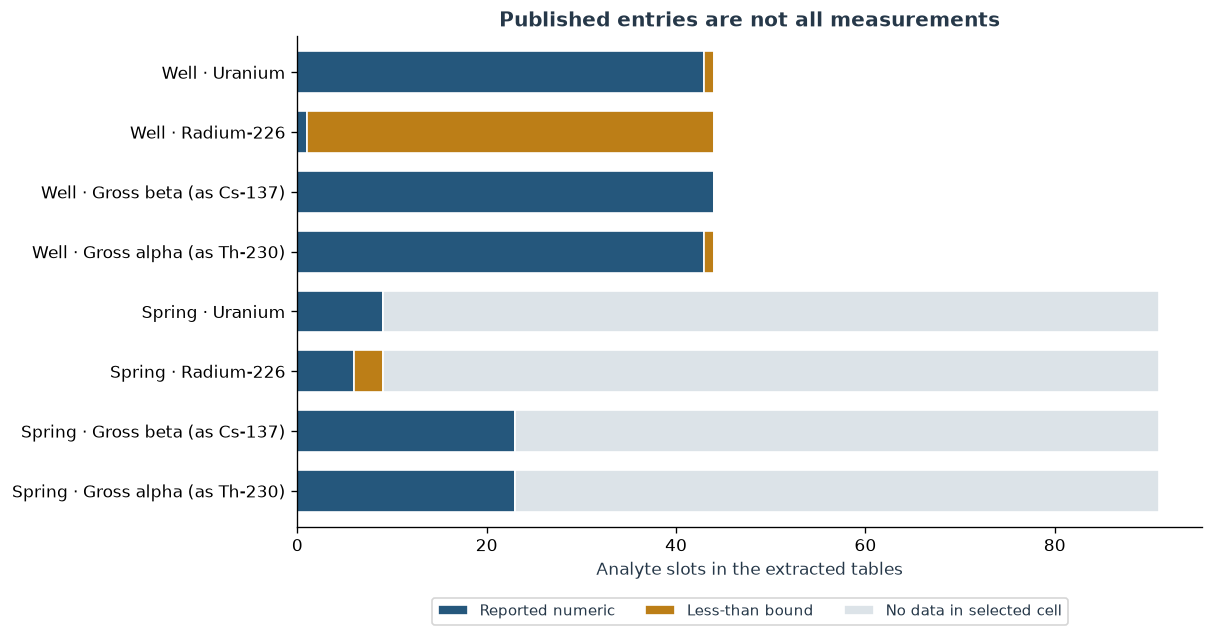

In [15]:
counts = (df.groupby(['site_type','analyte','qualifier']).size().unstack(fill_value=0)
          .reindex(columns=['reported_numeric','less_than','not_reported'], fill_value=0))
display(counts)
fig, ax = plt.subplots(figsize=(10,5.2), constrained_layout=True)
plot_counts = counts.copy()
plot_counts.index = [f'{kind.title()} · {LABELS[analyte]}' for kind,analyte in plot_counts.index]
plot_counts.rename(columns={'reported_numeric':'Reported numeric','less_than':'Less-than bound','not_reported':'No data in selected cell'}).plot.barh(
    stacked=True, ax=ax, color=[BLUE,GOLD,GRAY], edgecolor='white', width=.7)
ax.set(xlabel='Analyte slots in the extracted tables', ylabel='', title='Published entries are not all measurements')
ax.legend(loc='upper center', bbox_to_anchor=(.5,-.13), ncol=3, fontsize=9)
FIGURES.append(('01_reporting_coverage',fig)); plt.show()

## Uranium in the 44 public-supply wells

This plot uses **dissolved natural uranium in µg/L** (parameter 22703). Horizontal bars show the report's two-sigma estimates. The less-than result is plotted with an open triangle at its bound.

The dashed line is EPA's **30 µg/L uranium drinking-water MCL**, checked October 27, 2026. These are historical single samples with differing treatment stages. The report used a **proposed 20 µg/L value**; that historical comparison must not be relabeled as the current standard. [EPA Radionuclides Rule](https://www.epa.gov/dwreginfo/radionuclides-rule).

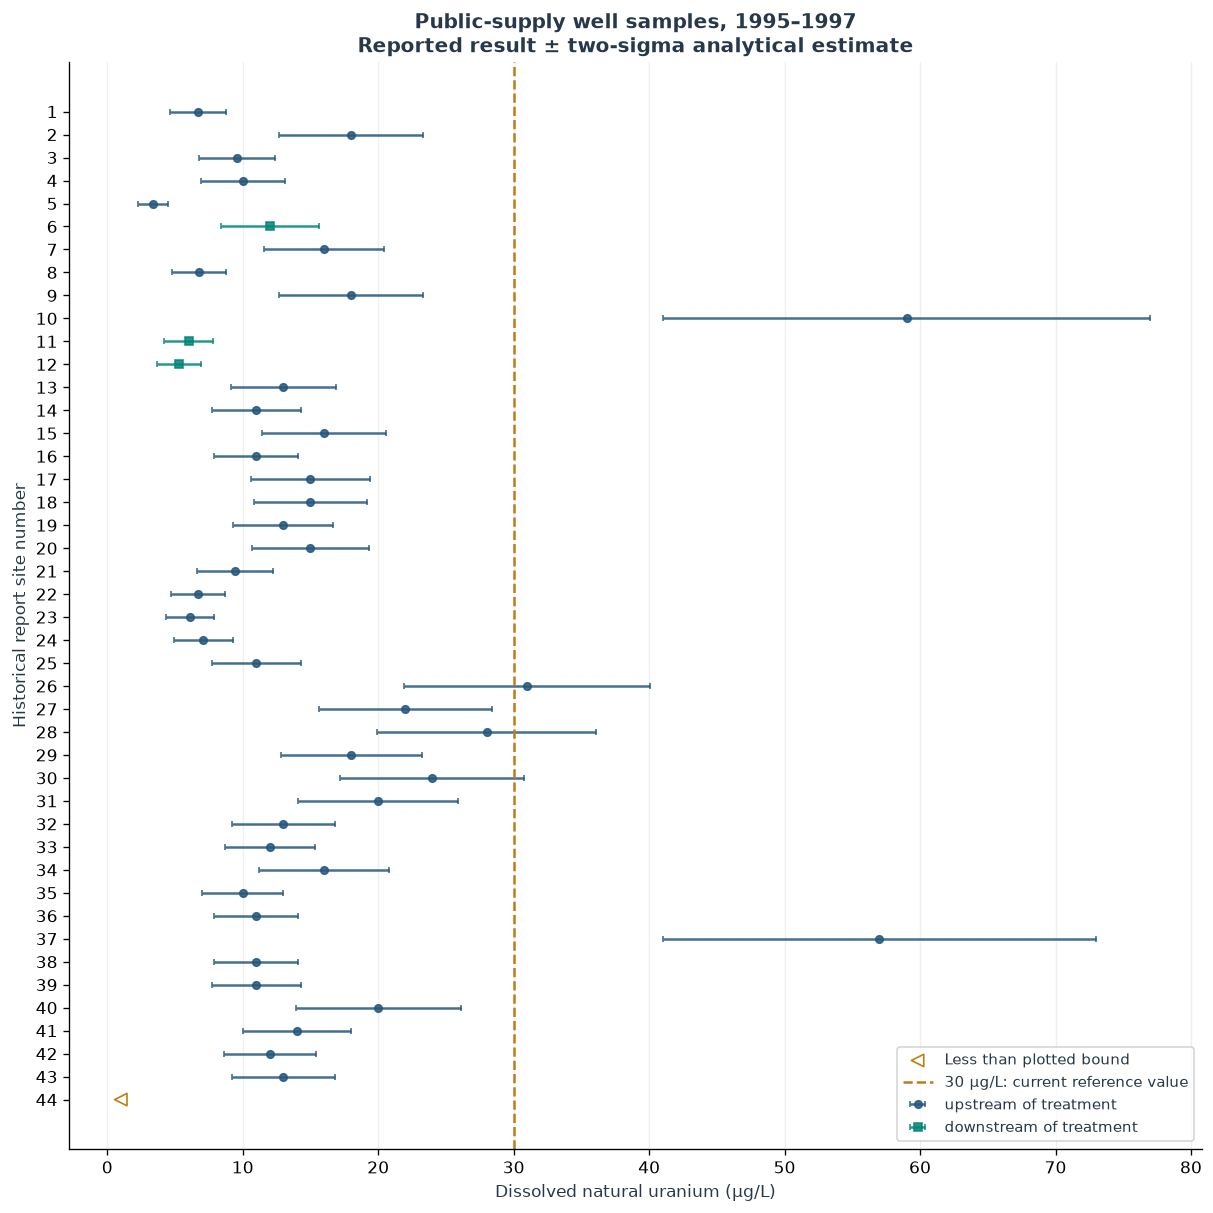

3 of 44 reported well results are numerically above 30 µg/L.


,site_id,sample_date_original,result_original,uncertainty_2sigma_original,treatment_stage
39,10,09-09-96,59,18,upstream of treatment
103,26,09-24-96,31,9.1,upstream of treatment
147,37,12-05-95,57,16,upstream of treatment


In [16]:
fig, ax = plt.subplots(figsize=(10,10), constrained_layout=True)
for stage, color, marker in [('upstream of treatment',BLUE,'o'),('downstream of treatment',TEAL,'s')]:
    sub = u[u.treatment_stage.eq(stage) & u.qualifier.eq('reported_numeric')]
    ax.errorbar(sub.result_numeric, sub.site_number, xerr=sub.uncertainty_2sigma,
                fmt=marker, ms=4.5, color=color, ecolor=color, alpha=.85, capsize=2, label=stage)
nd = u[u.qualifier.eq('less_than')]
ax.scatter(nd.reporting_bound, nd.site_number, marker='<', s=55, facecolors='none', edgecolors=GOLD, label='Less than plotted bound')
ax.axvline(30, color=GOLD, linestyle='--', lw=1.5, label='30 µg/L: current reference value')
ax.set(yticks=range(1,45), ylabel='Historical report site number', xlabel='Dissolved natural uranium (µg/L)',
       title='Public-supply well samples, 1995–1997\nReported result ± two-sigma analytical estimate')
ax.invert_yaxis(); ax.grid(axis='x', alpha=.2); ax.legend(loc='lower right', fontsize=9)
FIGURES.append(('02_well_uranium',fig)); plt.show()
above = u[u.result_numeric.gt(30)]
print(f'{len(above)} of 44 reported well results are numerically above 30 µg/L.')
display(above[['site_id','sample_date_original','result_original','uncertainty_2sigma_original','treatment_stage']])

**Read the graph:** Which sites have the largest reported uranium values? Does a bar crossing the reference line establish compliance or noncompliance? Why would sampling before versus after treatment matter?

The bars describe reported analytical uncertainty only. They do not capture changes since sampling, water consumption, household conditions, or the representativeness of the study sites. Do not truncate an uncertainty interval at a reference line or treat overlap as a formal regulatory decision rule.

## Gross alpha, gross beta, and radium-226 answer different questions

Gross alpha is reported here **as Th-230**; gross beta is reported **as Cs-137**. Those labels identify the reported analytical basis.

No regulatory line appears in the next plot. EPA's gross-alpha standard excludes uranium and radon; the report explains that its unadjusted gross-alpha results cannot simply be compared as compliance results (report pp. 34 and 38). EPA's radium standard is for **combined radium-226 and radium-228**, whereas this extraction contains radium-226. The beta/photon standard is dose-based; a gross-beta result in pCi/L cannot be compared directly to mrem/year. [EPA rule](https://www.epa.gov/dwreginfo/radionuclides-rule).

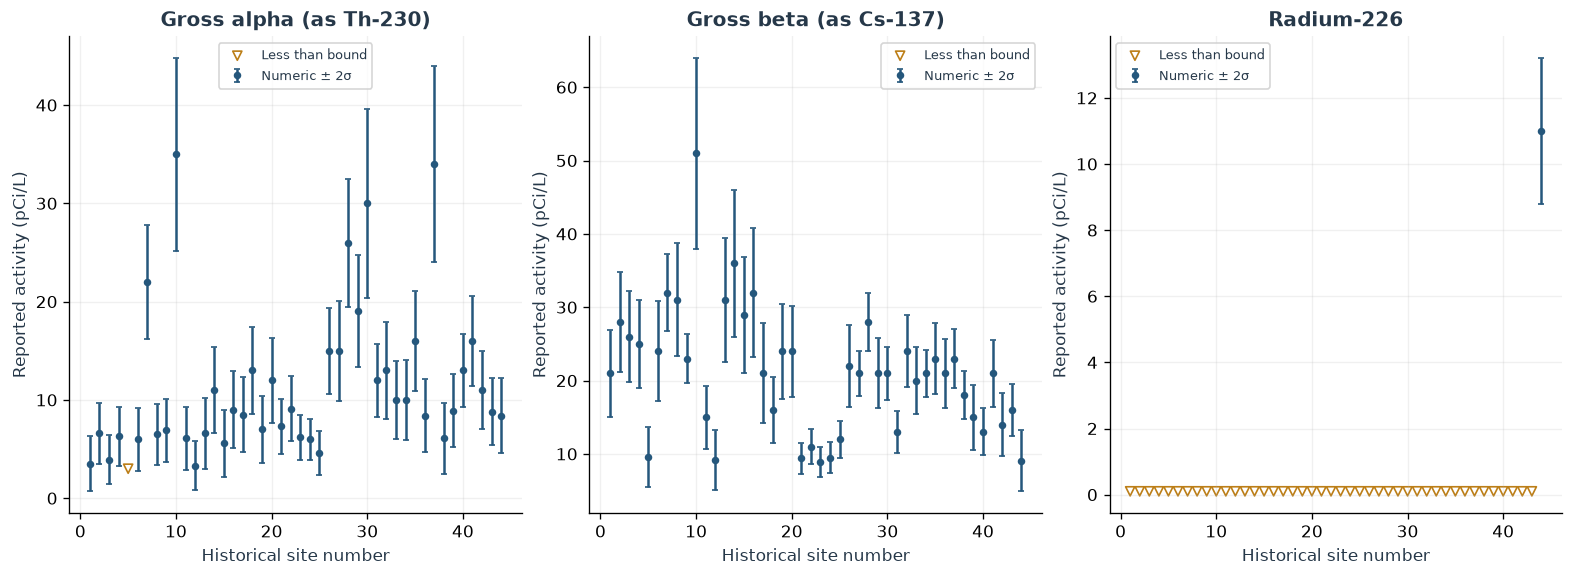

,site_id,result_original,unit,uncertainty_2sigma_original,aquifer,source_printed_page
174,44,11,pCi/L,2.21,Inyan Kara,60


In [17]:
fig, axes = plt.subplots(1,3,figsize=(13,4.7), constrained_layout=True)
for ax, analyte in zip(axes, ['gross_alpha','gross_beta','radium_226']):
    sub=well[well.analyte.eq(analyte)].copy()
    sub['site_number']=sub.site_id.astype(int)
    measured=sub[sub.qualifier.eq('reported_numeric')]
    bounded=sub[sub.qualifier.eq('less_than')]
    ax.errorbar(measured.site_number, measured.result_numeric, yerr=measured.uncertainty_2sigma,
                fmt='o', color=BLUE, ms=3.5, capsize=2, label='Numeric ± 2σ')
    ax.scatter(bounded.site_number, bounded.reporting_bound, marker='v', facecolors='none',
               edgecolors=GOLD, s=30, label='Less than bound')
    ax.set(title=LABELS[analyte],xlabel='Historical site number',ylabel='Reported activity (pCi/L)')
    ax.grid(alpha=.18); ax.legend(fontsize=8)
FIGURES.append(('03_other_analytes',fig)); plt.show()
display(well[well.analyte.eq('radium_226') & well.qualifier.eq('reported_numeric')][
    ['site_id','result_original','unit','uncertainty_2sigma_original','aquifer','source_printed_page']])

## Spring visits are not a radiation time series

Here the time axis shows all dates listed for each spring in the selected Table 13 pages. Open circles mean a listed visit has `--` for uranium. Filled circles mean a uranium result was reported. **An open circle is not a zero or a nondetect.** Blank space away from these markers means no visit is represented by this extraction.

This plot is about the report's measurement coverage, not the whole monitoring history of Pine Ridge. Later measurements may exist elsewhere.

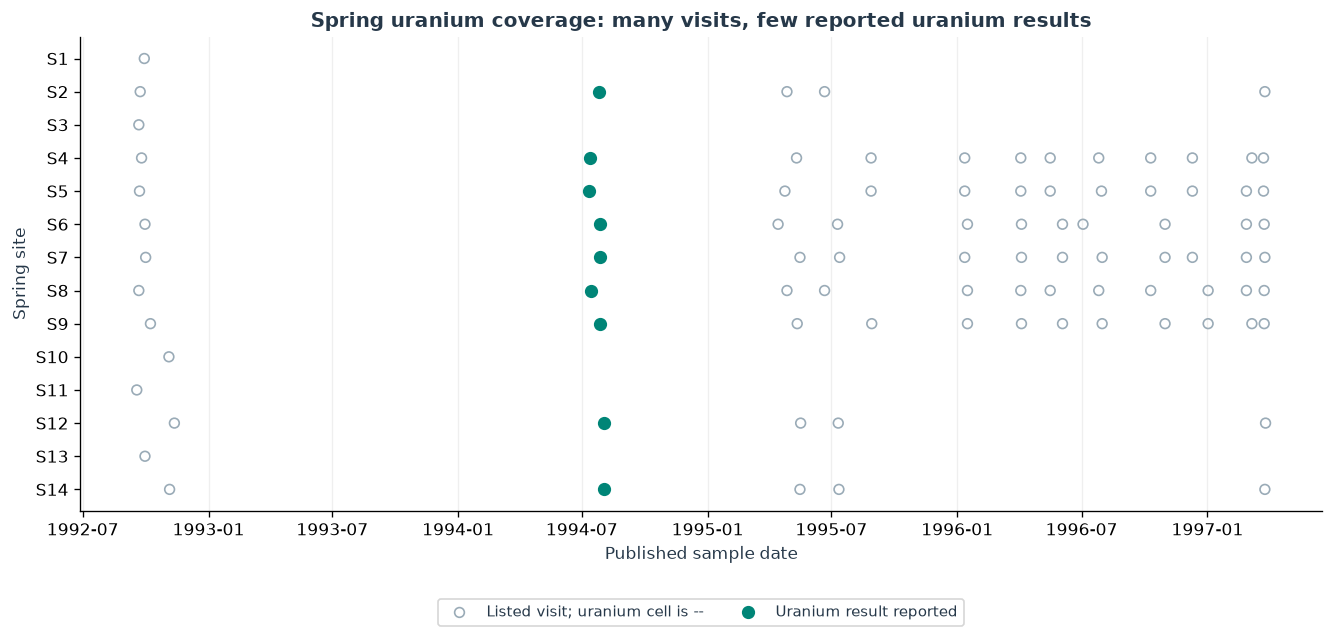

91 listed spring visits; 9 uranium results at 9 sites.


,site_id,sample_date_original,result_original,unit,uncertainty_2sigma_original
187,S2,07-26-94,7.1,ug/L,2.2
211,S4,07-13-94,3.3,ug/L,1.1
259,S5,07-12-94,2.1,ug/L,0.7
307,S6,07-27-94,11,ug/L,3.2
351,S7,07-28-94,10,ug/L,3.0
399,S8,07-14-94,13,ug/L,3.7
447,S9,07-27-94,9.6,ug/L,2.8
503,S12,08-02-94,7.2,ug/L,2.2
527,S14,08-03-94,7.0,ug/L,2.1


In [18]:
su = spring[spring.analyte.eq('uranium')].copy()
su['site_number'] = su.site_id.str[1:].astype(int)
fig, ax = plt.subplots(figsize=(11,5.2), constrained_layout=True)
missing = su[su.qualifier.eq('not_reported')]
reported = su[su.has_result]
ax.scatter(missing.sample_date, missing.site_number, s=34, facecolors='none', edgecolors='#9aabb7', label='Listed visit; uranium cell is --')
ax.scatter(reported.sample_date, reported.site_number, s=48, color=TEAL, label='Uranium result reported', zorder=3)
ax.set(yticks=range(1,15), yticklabels=[f'S{i}' for i in range(1,15)], ylabel='Spring site', xlabel='Published sample date',
       title='Spring uranium coverage: many visits, few reported uranium results')
ax.invert_yaxis(); ax.grid(axis='x',alpha=.2)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.17),ncol=2,fontsize=9)
FIGURES.append(('04_spring_uranium_coverage',fig)); plt.show()
print(f'{len(su)} listed spring visits; {su.has_result.sum()} uranium results at {reported.site_id.nunique()} sites.')
display(reported[['site_id','sample_date_original','result_original','unit','uncertainty_2sigma_original']])

### Compare reported spring uranium values without filling gaps

The nine reported uranium results are from 1994. The next plot includes only the reported values and their analytical uncertainties.

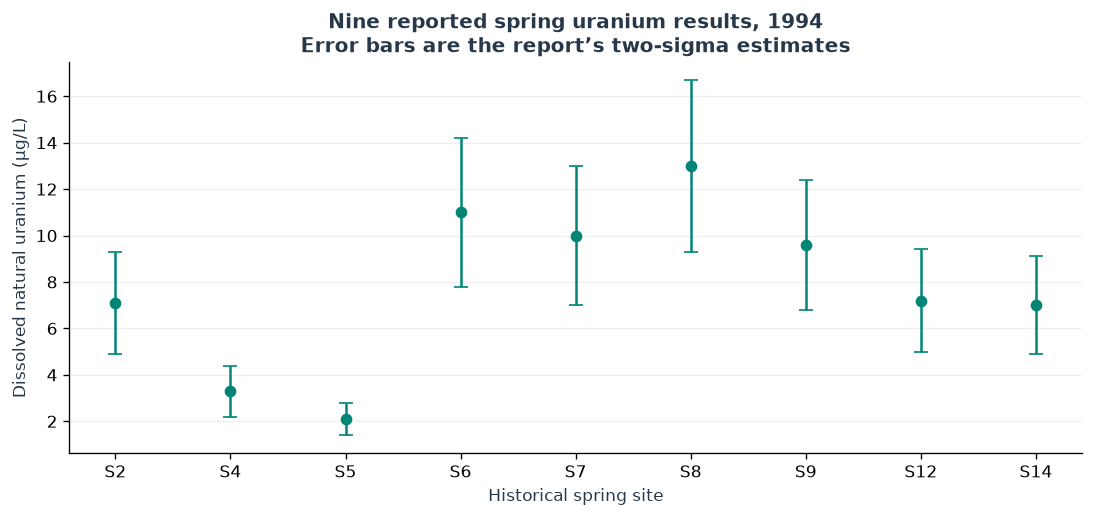

In [19]:
reported = reported.sort_values('site_number')
fig, ax = plt.subplots(figsize=(9,4.2), constrained_layout=True)
ax.errorbar(reported.site_id, reported.result_numeric, yerr=reported.uncertainty_2sigma,
            fmt='o', color=TEAL, capsize=4, ms=6)
ax.set(xlabel='Historical spring site',ylabel='Dissolved natural uranium (µg/L)',
       title='Nine reported spring uranium results, 1994\nError bars are the report’s two-sigma estimates')
ax.grid(axis='y',alpha=.2)
FIGURES.append(('05_spring_uranium',fig)); plt.show()

## Dates, treatment stage, and the limits of inference

The well sampling-year count below excludes sites 27 and 42 because their source dates disagree. It counts site-level records. The value plots above retain their printed concentrations.

The study selected public-supply wells and springs for particular questions. Without a sampling design for estimating reservation-wide prevalence, these results should not become a statement such as “X% of Pine Ridge residents were exposed.” A few dates per site also cannot establish a long-term trend.

In [20]:
dates = well[well.analyte.eq('gross_alpha') & ~well.date_conflict].copy()
dates['year'] = dates.sample_date.dt.year
display(dates.groupby(['year','treatment_stage']).size().unstack(fill_value=0).rename_axis('Sampling year'))
display(well[well.analyte.eq('uranium')].groupby('aquifer').agg(
    sampled_sites=('site_id','nunique'), reported_numeric=('result_numeric','count'),
    less_than_results=('qualifier',lambda s: s.eq('less_than').sum())))

treatment_stage,downstream of treatment,upstream of treatment
Sampling year,,
1995,0,14
1996,1,14
1997,2,11


,sampled_sites,reported_numeric,less_than_results
aquifer,,,
Alluvium,1,1,0
Arikaree,42,42,0
Inyan Kara,1,0,1


## A reproducible inspection exercise

Choose an analyte, site type, and optional historical site number. Inspect original strings, units, and source pages before interpreting the values. This exercise filters existing records; it does not generate predictions.

In [ ]:
SELECT_ANALYTE = 'uranium'       # uranium, gross_alpha, gross_beta, radium_226
SELECT_SITE_TYPE = 'well'       # well or spring
SELECT_SITE = None              # ex. '10' for a well or 'S8' for a spring
assert SELECT_ANALYTE in ANALYTES and SELECT_SITE_TYPE in ['well','spring']
selected = df[df.analyte.eq(SELECT_ANALYTE) & df.site_type.eq(SELECT_SITE_TYPE)]
if SELECT_SITE is not None:
    selected = selected[selected.site_id.eq(str(SELECT_SITE))]
display(selected[['site_id','sample_date_original','result_original','unit','qualifier',
                  'uncertainty_2sigma_original','treatment_stage','source_printed_page','date_conflict']])

,site_id,sample_date_original,result_original,unit,qualifier,uncertainty_2sigma_original,treatment_stage,source_printed_page,date_conflict
3,1,09-26-96,6.7,ug/L,reported_numeric,2.1,upstream of treatment,61,False
7,2,08-29-96,18,ug/L,reported_numeric,5.3,upstream of treatment,61,False
11,3,08-21-96,9.6,ug/L,reported_numeric,2.8,upstream of treatment,61,False
15,4,08-20-96,10,ug/L,reported_numeric,3.1,upstream of treatment,61,False
19,5,06-26-97,3.4,ug/L,reported_numeric,1.1,upstream of treatment,61,False
23,6,08-22-96,12,ug/L,reported_numeric,3.6,downstream of treatment,61,False
27,7,07-08-97,16,ug/L,reported_numeric,4.4,upstream of treatment,61,False
31,8,09-05-96,6.8,ug/L,reported_numeric,2.0,upstream of treatment,61,False
35,9,12-07-95,18,ug/L,reported_numeric,5.3,upstream of treatment,61,False
39,10,09-09-96,59,ug/L,reported_numeric,18,upstream of treatment,61,False


## Extend the investigation with the community

**Evidence supported here:** the published historical samples contain measurable uranium and radioactivity, with distinct analytes, qualifiers, and uneven coverage. The results justify examining the community's questions carefully.                                                         

Work through these questions before extending the analysis:

1. Which contemporary measurements would answer the chosen question, and should sampling distinguish source water, post-treatment water, and household taps?
2. Which locations, dates, laboratories, analytical methods, and detection limits would be needed to compare old and new records?
3. Who decides what can be collected, retained, linked, mapped, and released? How should results be returned to the community?
4. What evidence would distinguish geogenic uranium mobility from an additional human contribution? Neither concentration nor proximity alone resolves that question.
5. Which gaps should be represented as “not known” rather than filled by interpolation?

The companion [source inventory](source_inventory.md) identifies additional leads. Two are especially relevant:

- [Swift Bird, Navarre-Sitchler, and Singha (2020)](https://doi.org/10.1016/j.apgeochem.2020.104522), a later groundwater study. Its methods distinguish 107 direct uranium measurements from estimates for other wells.                                                                      
- [Defenders of the Black Hills, March 2011](https://www.defendblackhills.org/document/waterreport32011.pdf), a community-origin regional water report. Verify relevant laboratory records, geography, and units before numerical integration; retain the distinction between analytical results and interpretation.

**Short writing assignment:** write a caption for one figure that names the analyte, medium, dates, units, sample count, and one limitation. Then write one question for community-directed follow-up that the figure cannot answer.

A later mapping module can use validated locations and an appropriate release scale.

## Export the evidence and figures

The following cell writes the original snapshot, interpreted table, coverage counts, figures, and run metadata to `radiation_results/`. It does not overwrite the source dataset. Hashes link the run to the supplied snapshot.

In [22]:
export_dir = Path('radiation_results')
export_dir.mkdir(exist_ok=True)
(export_dir/'source_snapshot.csv').write_bytes(raw_csv)
df.to_csv(export_dir/'interpreted_results.csv',index=False)
counts.to_csv(export_dir/'reporting_coverage.csv')
for name, fig in FIGURES:
    fig.savefig(export_dir/f'{name}.png',dpi=170,bbox_inches='tight')
run_metadata = {
    'source_doi':'10.3133/wri994063', 'source_csv_sha256':EXPECTED_CSV_SHA256,
    'data_type':'published historical laboratory results; no simulated values',
    'analyte_slots':len(df), 'slots_with_results_or_bounds':int(df.has_result.sum()),
    'well_sites':int(well.site_id.nunique()), 'spring_sites':int(spring.site_id.nunique()),
    'well_uranium_results_above_30_ug_L':int(u.result_numeric.gt(30).sum()),
    'versions': {'python':sys.version.split()[0], 'numpy':np.__version__,
                 'pandas':pd.__version__, 'matplotlib':matplotlib.__version__},
    'date_conflicts':'Sites 27 and 42 retained and excluded from date-based well summary',
}
(export_dir/'run_metadata.json').write_text(json.dumps(run_metadata,indent=2),encoding='utf-8')
print('Saved tables, five figures, and run metadata to',export_dir.resolve())

Saved tables, five figures, and run metadata to C:\Users\gekek\Documents\pine-ridge-radiation\radiation_results


## References and provenance

- Heakin, A.J., 2000. USGS WRI 99-4063. [Publication](https://pubs.usgs.gov/publication/wri994063), [original PDF](https://pubs.usgs.gov/wri/wri994063/wri994063.pdf). Tables 3, 13, 14; sampling methods p. 13; interpretation pp. 34 and 38. Source retrieved October 27, 2026.
- US EPA. [Radionuclides Rule](https://www.epa.gov/dwreginfo/radionuclides-rule), consulted October 27, 2026. Uranium reference is for community drinking-water regulation; no formal compliance analysis is performed.
- Swift Bird, K., Navarre-Sitchler, A., and Singha, K., 2020. [Applied Geochemistry 114, 104522](https://doi.org/10.1016/j.apgeochem.2020.104522). Further reading; its measurements are not incorporated in this dataset.
- White Face, C., 2011. [Report on Water Tests for Radioactive Contamination](https://www.defendblackhills.org/document/waterreport32011.pdf). Further reading; its measurements are not incorporated in this dataset.

The extraction preserves selected published result strings and analytical uncertainties; it is not a replacement for the original report or laboratory records. `data/provenance.json` contains the original PDF and CSV checksums. The notebook includes checks against source counts and a visually reviewed uranium vector. Exact site coordinates and new private records are not included.